## 1. Import bibliotek i wczytanie danych

# Analiza i Klasyfikacja Obrazów: JFIF vs PPM

Ten notebook zawiera:
1. Wczytanie i przygotowanie danych
2. Eksploracyjną analizę danych z wizualizacjami
3. Modele uczenia maszynowego do klasyfikacji obrazów
4. Ocenę wydajności modeli

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
import joblib
import warnings
warnings.filterwarnings('ignore')

# Ustawienia wizualizacji
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

In [36]:
# Ustawienia wielkości czcionek dla wykresów
font_size = 20  # Domyślna wielkość czcionki (można zmieniać: 10, 12, 14, 16, itp.)

In [2]:
# Wczytanie danych
df_jfif = pd.read_csv('results_jfif.csv')
df_ppm = pd.read_csv('results_ppm.csv')

# Dodanie etykiet
df_jfif['label'] = 'jfif'
df_ppm['label'] = 'ppm'

# Połączenie danych
df = pd.concat([df_jfif, df_ppm], ignore_index=True)

print(f"Łączna liczba próbek: {len(df)}")
print(f"Liczba próbek JFIF: {len(df_jfif)}")
print(f"Liczba próbek PPM: {len(df_ppm)}")
print(f"\nKształt danych: {df.shape}")
print(f"\nPierwsze wiersze:")
df.head()

Łączna liczba próbek: 22338
Liczba próbek JFIF: 11000
Liczba próbek PPM: 11338

Kształt danych: (22338, 18)

Pierwsze wiersze:


,filename,extension,blockiness_0,blockiness_1,blockiness_2,blockiness_3,blockiness_4,blockiness_5,blockiness_6,blockiness_7,blockiness_max,blockiness_mean,blockiness_std,energy_mean,energy_std,estimated_quality,psnr,label
0,person_0000,.jfif,0.982579,1.023817,0.983430,1.015128,0.978278,1.017822,0.984327,1.015049,1.023817,1.000054,0.018151,171.702927,219.525040,95,48.239087,jfif
1,person_0001,.jfif,0.974208,1.026013,0.980004,1.023358,0.958742,1.025917,0.991914,1.020627,1.026013,1.000098,0.025377,175.390381,138.365646,95,48.153348,jfif
2,person_0002,.jfif,0.976464,1.021469,0.982523,1.022847,0.965297,1.023260,0.988686,1.020104,1.023260,1.000081,0.022693,274.787964,373.415070,95,47.177045,jfif
3,person_0003,.jfif,0.957845,1.046134,0.976205,1.038396,0.954498,1.027543,0.968721,1.032222,1.046134,1.000196,0.036728,156.187531,123.051079,95,48.209320,jfif
4,person_0004,.jfif,0.984663,1.020880,0.979691,1.017513,0.978981,1.019925,0.988607,1.010116,1.020880,1.000047,0.017540,152.209930,145.642273,95,48.491525,jfif


## 2. Przygotowanie danych do modelowania

In [3]:
# Wybór cech (bez filename i extension)
feature_columns = ['blockiness_0', 'blockiness_1', 'blockiness_2', 'blockiness_3', 
                   'blockiness_4', 'blockiness_5', 'blockiness_6', 'blockiness_7',
                   'blockiness_max', 'blockiness_mean', 'blockiness_std',
                   'energy_mean', 'energy_std', 'estimated_quality', 'psnr']

X = df[feature_columns]
y = df['label']

# Konwersja etykiet na wartości binarne (0 = jfif, 1 = ppm)
y_binary = (y == 'ppm').astype(int)

# Podział na zbiór treningowy, walidacyjny i testowy z losowym mieszaniem
# Najpierw oddzielamy zbiór testowy (20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y_binary, test_size=0.2, random_state=42, stratify=y_binary, shuffle=True)

# Następnie dzielimy pozostałe dane na treningowy (64%) i walidacyjny (16%)
# 0.2 z 0.8 = 0.16 całości
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp, shuffle=True)

# Standaryzacja danych
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Zbiór treningowy: {X_train.shape} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Zbiór walidacyjny: {X_val.shape} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Zbiór testowy: {X_test.shape} ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nRozkład klas w zbiorze treningowym:")
print(pd.Series(y_train).value_counts())
print(f"\nRozkład klas w zbiorze walidacyjnym:")
print(pd.Series(y_val).value_counts())
print(f"\nRozkład klas w zbiorze testowym:")
print(pd.Series(y_test).value_counts())

Zbiór treningowy: (14296, 15) (64.0%)
Zbiór walidacyjny: (3574, 15) (16.0%)
Zbiór testowy: (4468, 15) (20.0%)

Rozkład klas w zbiorze treningowym:
label
1    7256
0    7040
Name: count, dtype: int64

Rozkład klas w zbiorze walidacyjnym:
label
1    1814
0    1760
Name: count, dtype: int64

Rozkład klas w zbiorze testowym:
label
1    2268
0    2200
Name: count, dtype: int64


## 3. Wizualizacje danych

### 3.1. Wykres liniowy zbiorczy - Blockiness (8 linii dla każdej grupy)

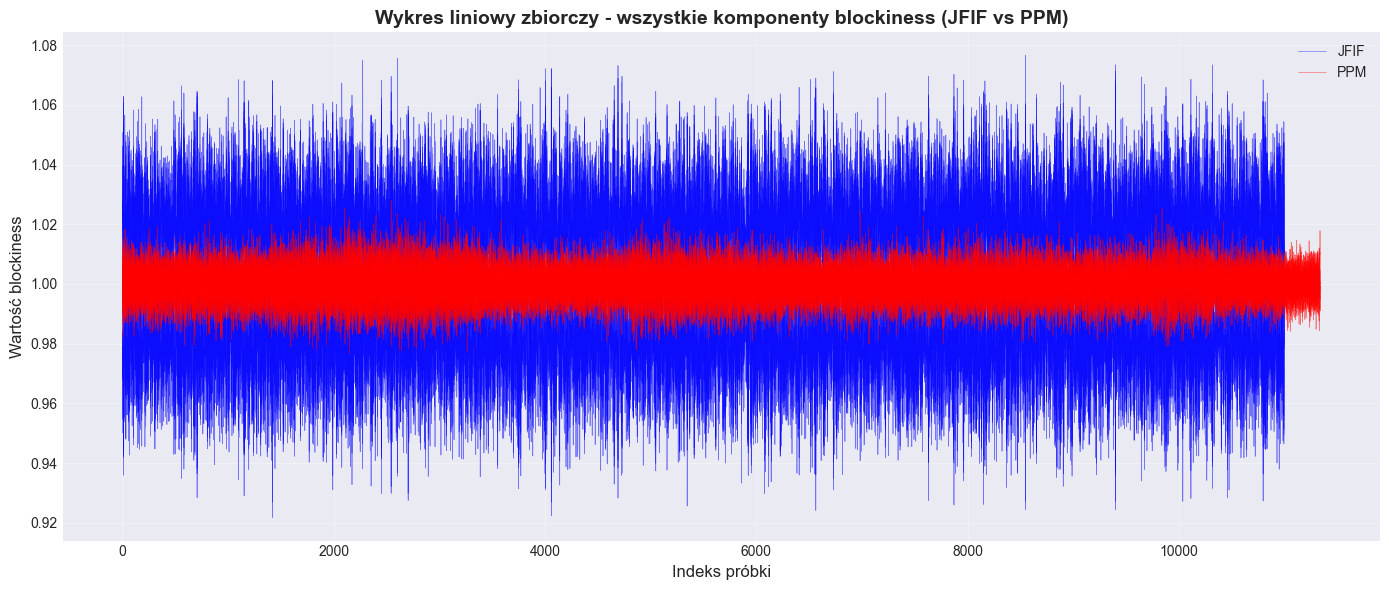

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

blockiness_cols = ['blockiness_0', 'blockiness_1', 'blockiness_2', 'blockiness_3', 
                   'blockiness_4', 'blockiness_5', 'blockiness_6', 'blockiness_7']

# Wykres dla JFIF
for col in blockiness_cols:
    values_jfif = df_jfif[col].values
    ax.plot(range(len(values_jfif)), values_jfif, alpha=0.5, linewidth=0.5, color='blue', label='JFIF' if col == blockiness_cols[0] else '')

# Wykres dla PPM
for col in blockiness_cols:
    values_ppm = df_ppm[col].values
    # if col != 'blockiness_0':
    #     continue
    ax.plot(range(len(values_ppm)), values_ppm, alpha=0.5, linewidth=0.5, color='red', label='PPM' if col == blockiness_cols[0] else '')

ax.set_xlabel('Indeks próbki', fontsize=font_size)
ax.set_ylabel('Wartość blockiness', fontsize=font_size)
ax.set_title('Wykres liniowy zbiorczy - wszystkie komponenty blockiness (JFIF vs PPM)', fontsize=font_size+2, fontweight='bold')
ax.legend(fontsize=font_size)
ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', which='major', labelsize=font_size-2)
plt.tight_layout()
plt.show()

### 3.2. Boxploty - porównanie kluczowych wskaźników

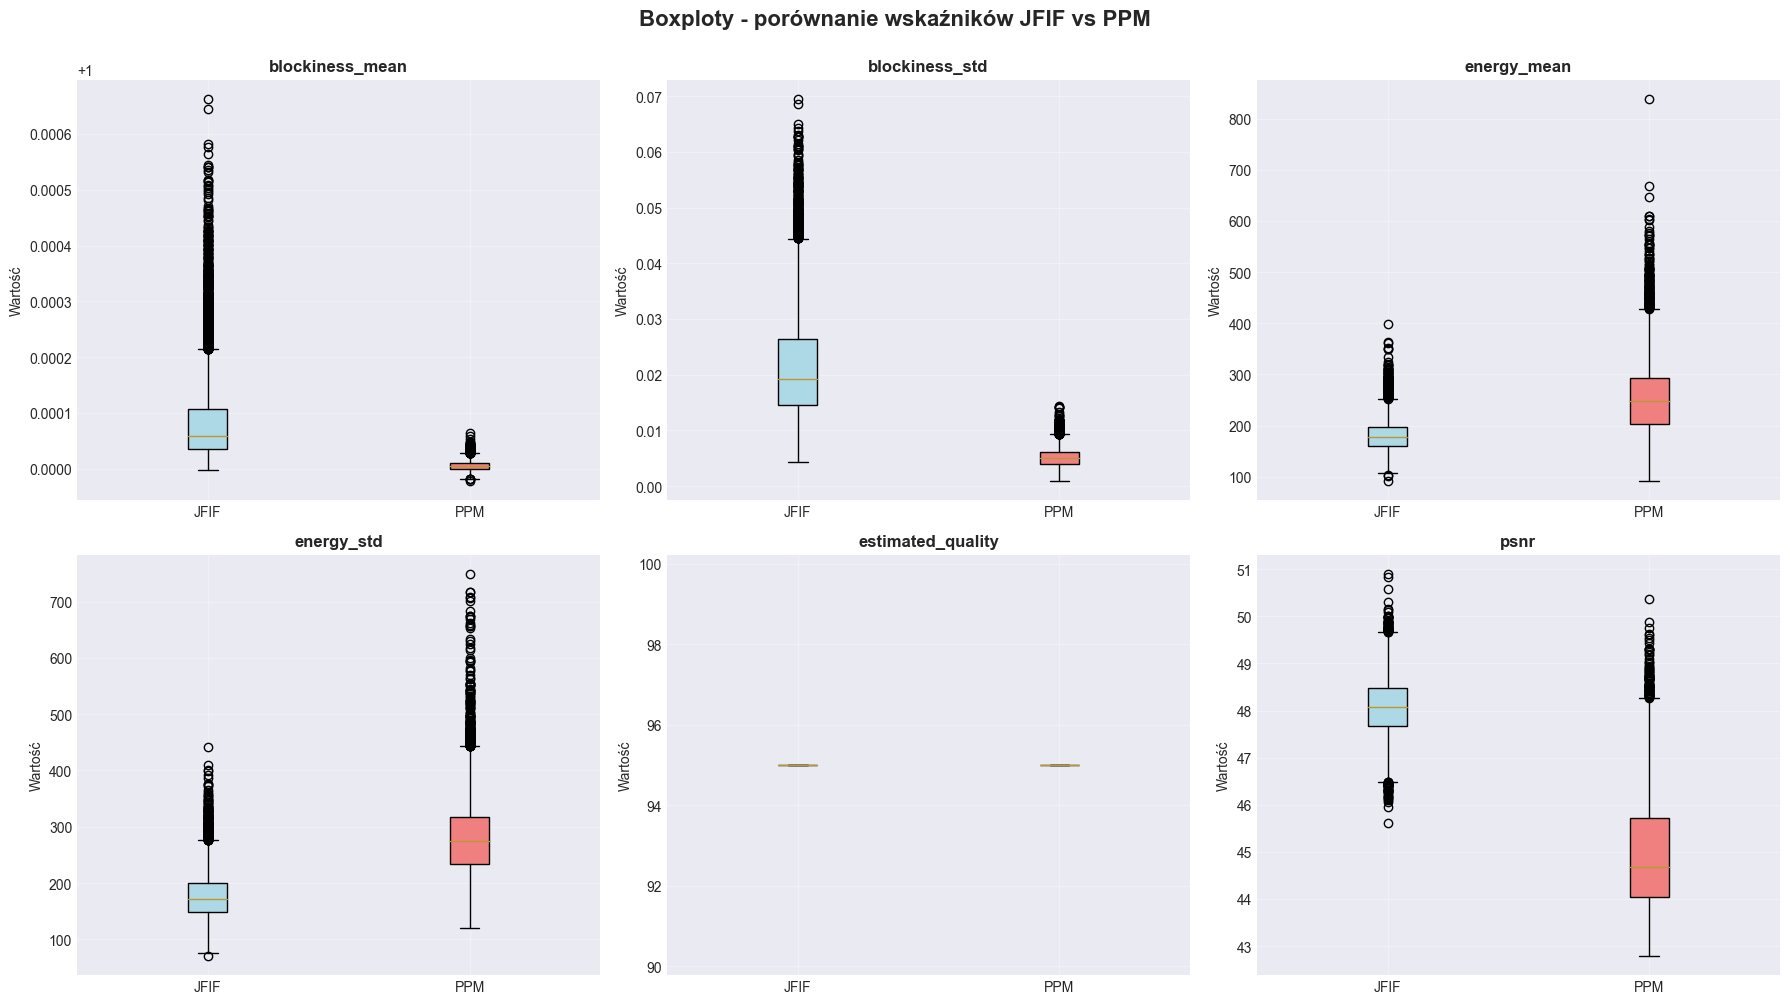

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

features_to_plot = ['blockiness_mean', 'blockiness_std', 'energy_mean', 'energy_std', 'estimated_quality', 'psnr']

for i, feature in enumerate(features_to_plot):
    data_to_plot = [df_jfif[feature], df_ppm[feature]]
    bp = axes[i].boxplot(data_to_plot, labels=['JFIF', 'PPM'], patch_artist=True)
    
    # Kolorowanie
    colors = ['lightblue', 'lightcoral']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    
    axes[i].set_title(f'{feature}', fontsize=font_size, fontweight='bold')
    axes[i].set_ylabel('Wartość', fontsize=font_size-2)
    axes[i].tick_params(axis='both', which='major', labelsize=font_size-2)
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Boxploty - porównanie wskaźników JFIF vs PPM', fontsize=font_size+4, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### 3.3. Histogramy - rozkłady wskaźników

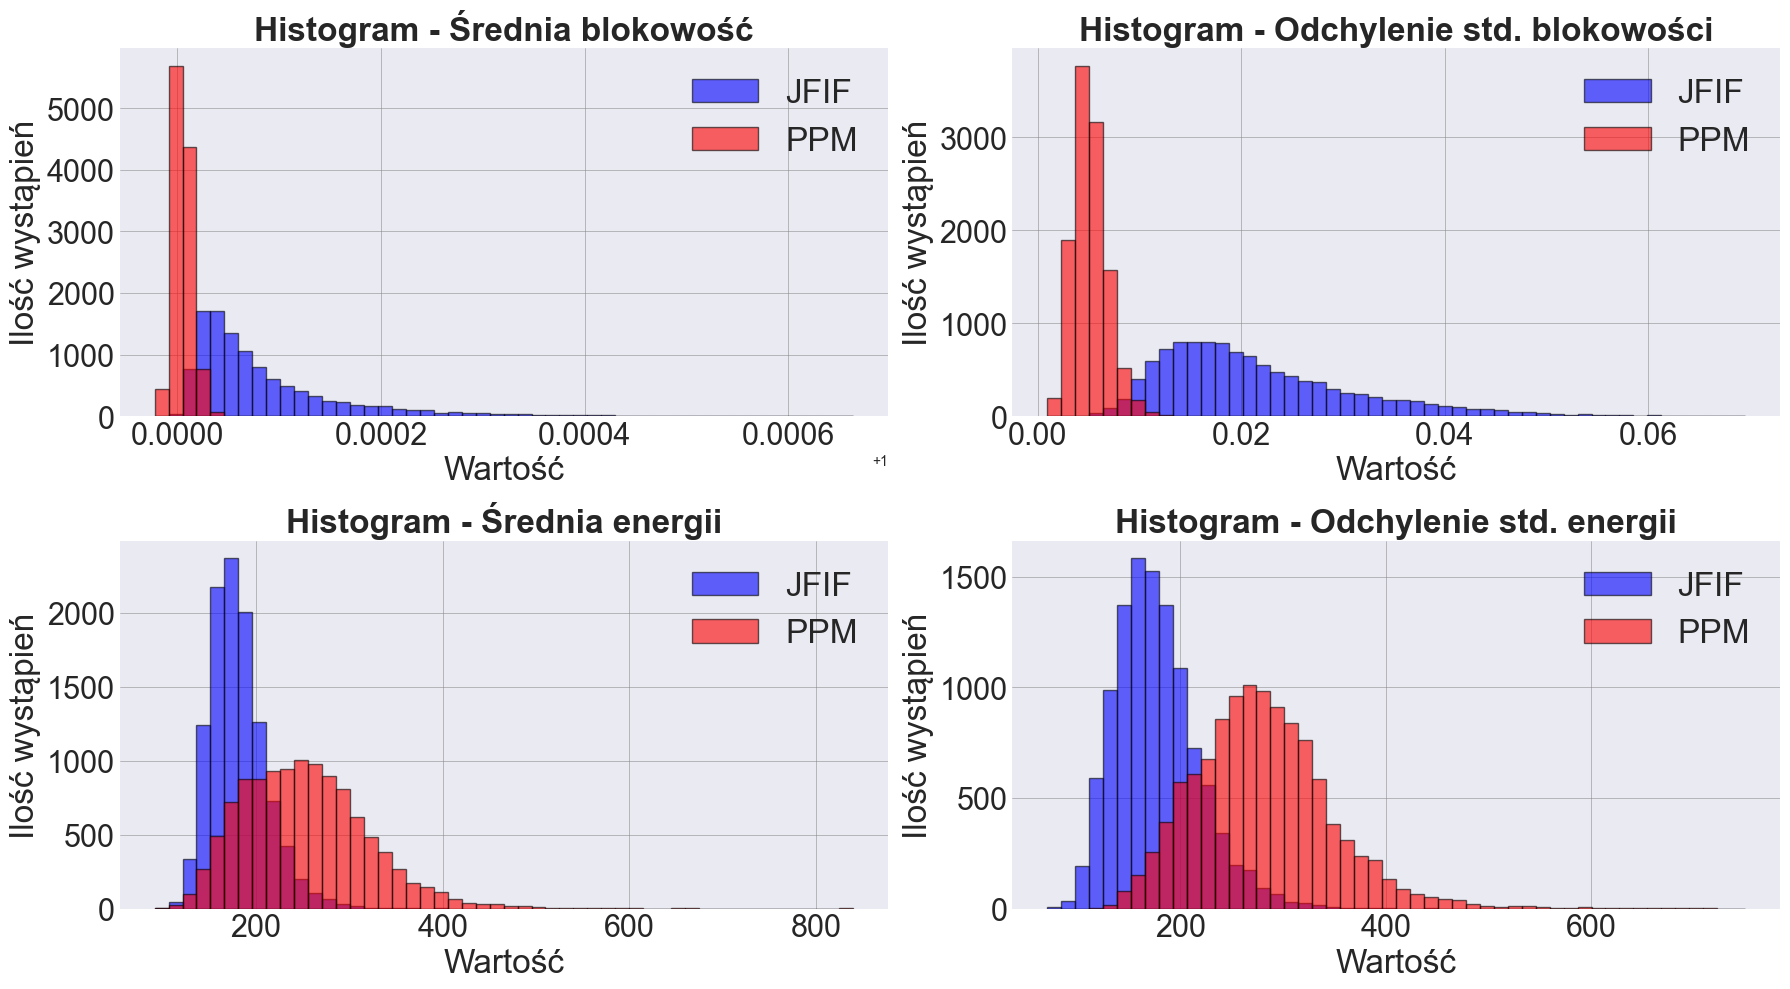

In [42]:

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.ravel()

# Exclude 'psnr' and 'estimated_quality' from features_to_plot
features_to_plot_filtered = [f for f in features_to_plot if f not in ['psnr', 'estimated_quality']]

# Polish names for features
polish_names = {
    'blockiness_mean': 'Średnia blokowość',
    'blockiness_std': 'Odchylenie std. blokowości',
    'energy_mean': 'Średnia energii',
    'energy_std': 'Odchylenie std. energii'
}

for i, feature in enumerate(features_to_plot_filtered):
    # Calculate common range for both datasets
    min_val = min(df_jfif[feature].min(), df_ppm[feature].min())
    max_val = max(df_jfif[feature].max(), df_ppm[feature].max())
    hist_range = (min_val, max_val)
    
    # Calculate bin width as 5% of the plot range
    bin_width = (max_val - min_val) * 0.02
    bins = np.arange(min_val, max_val + bin_width, bin_width)
    
    axes[i].hist(df_jfif[feature], bins=bins, alpha=0.6, label='JFIF', color='blue', edgecolor='black', range=hist_range)
    axes[i].hist(df_ppm[feature], bins=bins, alpha=0.6, label='PPM', color='red', edgecolor='black', range=hist_range)
    axes[i].set_title(f'Histogram - {polish_names[feature]}', fontsize=font_size+4, fontweight='bold')
    axes[i].set_xlabel('Wartość', fontsize=font_size+4)
    axes[i].set_ylabel('Ilość wystąpień', fontsize=font_size+4)
    axes[i].legend(fontsize=font_size+4)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='both', which='major', labelsize=font_size+2)
    axes[i].locator_params(axis='x', nbins=6)
    axes[i].locator_params(axis='y', nbins=6)
    axes[i].ticklabel_format(style='plain', axis='both')
    axes[i].grid(True, which='both', linewidth=0.5, alpha=0.7, color='gray')

plt.tight_layout()
plt.show()

### 3.4. Wykresy liniowe - średnie wartości blockiness dla obu grup

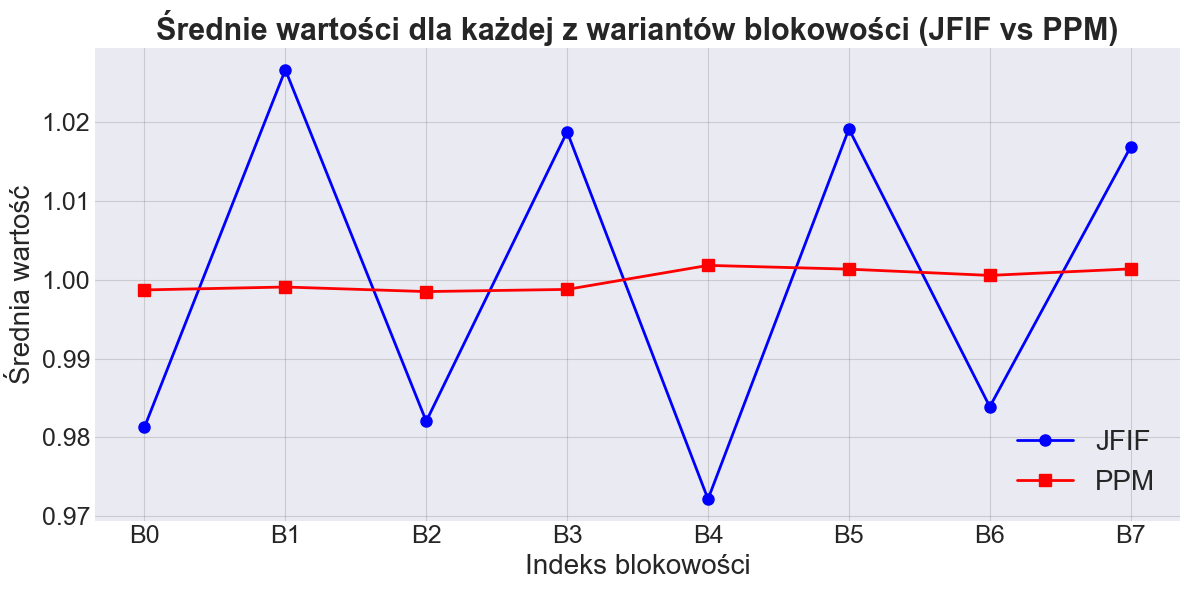

In [45]:
fig, ax = plt.subplots(figsize=(12, 6))

# Obliczenie średnich dla każdego blockiness
mean_jfif = [df_jfif[col].mean() for col in blockiness_cols]
mean_ppm = [df_ppm[col].mean() for col in blockiness_cols]

x_labels = ['B0', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7']

ax.plot(x_labels, mean_jfif, marker='o', linewidth=2, markersize=8, label='JFIF', color='blue')
ax.plot(x_labels, mean_ppm, marker='s', linewidth=2, markersize=8, label='PPM', color='red')

ax.set_xlabel('Indeks blokowości', fontsize=font_size)
ax.set_ylabel('Średnia wartość', fontsize=font_size)
ax.set_title('Średnie wartości dla każdej z wariantów blokowości (JFIF vs PPM)', fontsize=font_size+2, fontweight='bold')
ax.legend(fontsize=font_size)
ax.tick_params(axis='both', which='major', labelsize=font_size-2)
ax.grid(True, alpha=0.3, color='grey')
plt.tight_layout()
plt.show()

### 3.5. Zbiorczy wykres liniowy - wszystkie wskaźniki

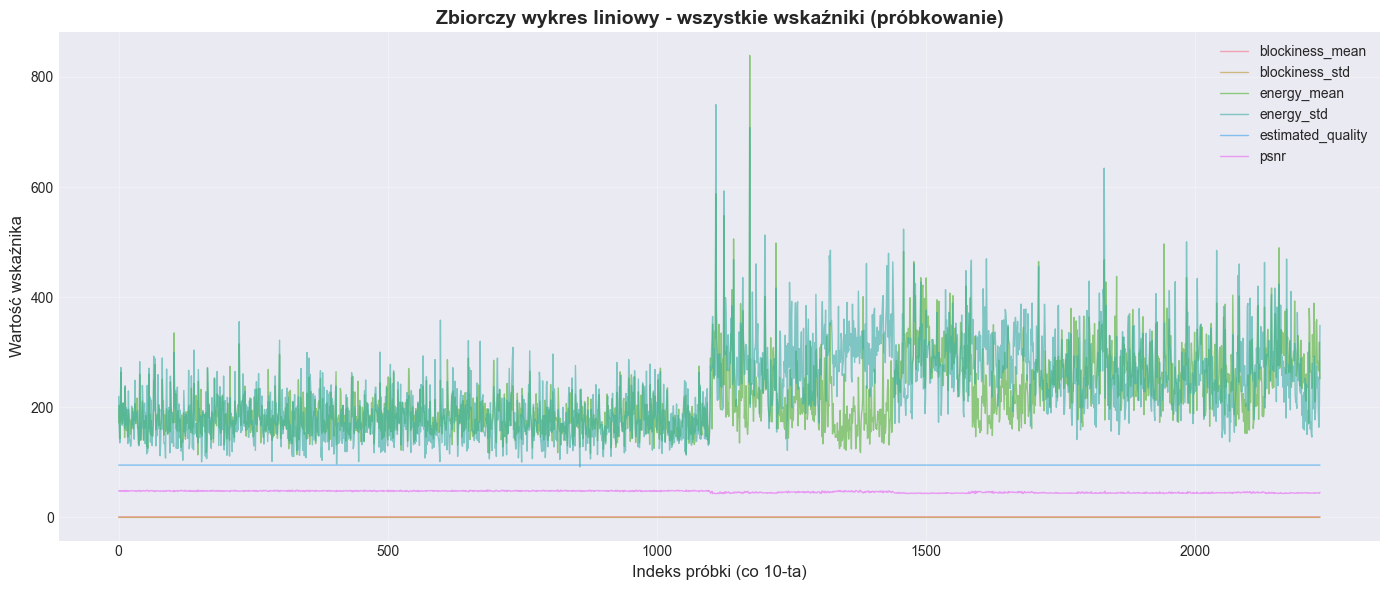

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

# Próbkowanie dla lepszej czytelności (każda 10. próbka)
sample_rate = 10
indices = range(0, min(len(df_jfif), len(df_ppm)), sample_rate)

for feature in features_to_plot:
    values_combined = df.iloc[::sample_rate][feature].values
    ax.plot(range(len(values_combined)), values_combined, alpha=0.6, linewidth=1, label=feature)

ax.set_xlabel('Indeks próbki (co 10-ta)', fontsize=font_size)
ax.set_ylabel('Wartość wskaźnika', fontsize=font_size)
ax.set_title('Zbiorczy wykres liniowy - wszystkie wskaźniki (próbkowanie)', fontsize=font_size+2, fontweight='bold')
ax.legend(loc='best', fontsize=font_size-2)
ax.tick_params(axis='both', which='major', labelsize=font_size-2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.6. Macierz korelacji

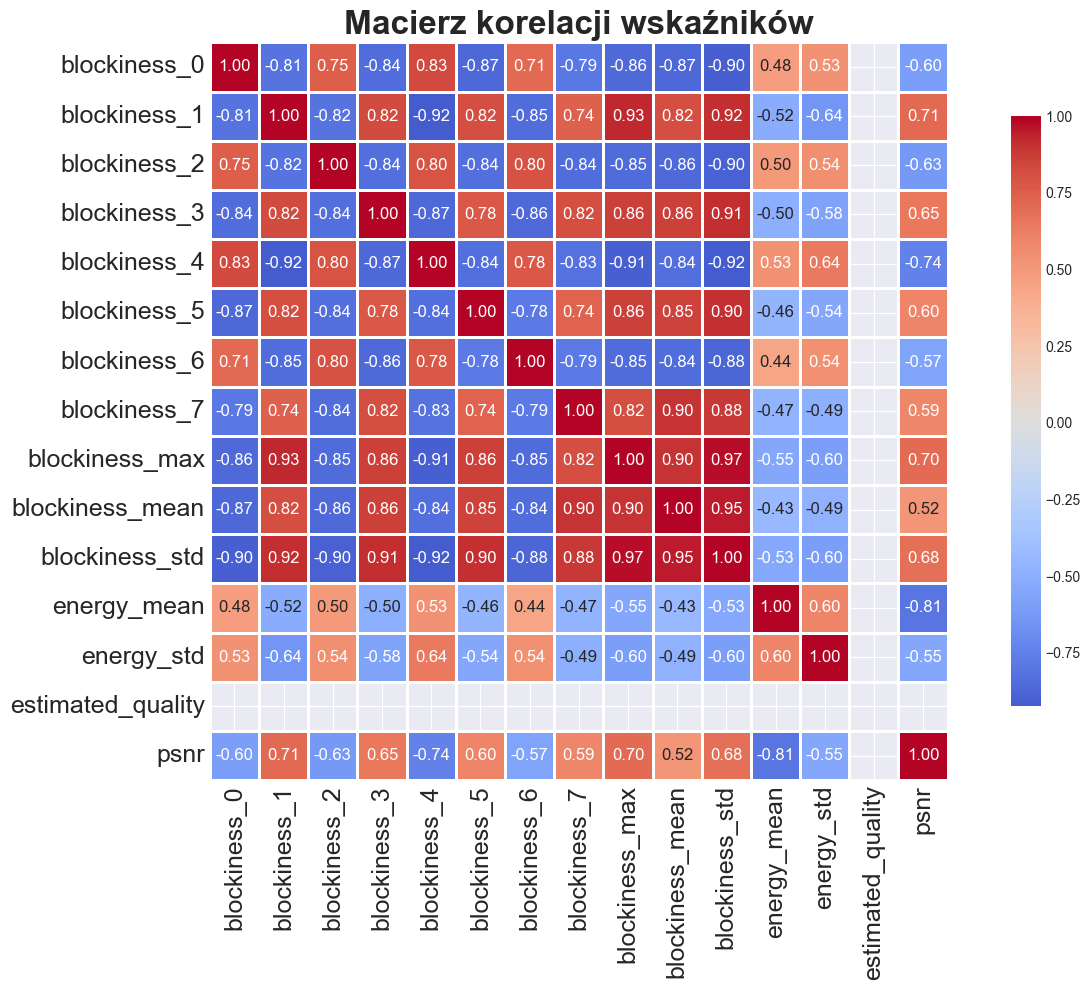

In [49]:
fig, ax = plt.subplots(figsize=(14, 10))

correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax, annot_kws={"fontsize": font_size-8})

ax.set_title('Macierz korelacji wskaźników', fontsize=font_size+4, fontweight='bold')
ax.tick_params(axis='both', which='major', labelsize=font_size-2)
plt.tight_layout()
plt.show()

## 4. Modele uczenia maszynowego

### 4.1. Trening różnych algorytmów klasyfikacji

In [52]:
# Definicja modeli
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

# Słownik na wyniki
results = {}

# Trening i ewaluacja modeli
print("Trening modeli...\n")
for name, model in models.items():
    print(f"Trening: {name}...")
    model.fit(X_train_scaled, y_train)
    
    # Predykcje na zbiorze walidacyjnym
    y_val_pred = model.predict(X_val_scaled)
    y_val_pred_proba = model.predict_proba(X_val_scaled)[:, 1]
    
    # Predykcje na zbiorze testowym
    y_test_pred = model.predict(X_test_scaled)
    y_test_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    # Metryki na zbiorze walidacyjnym
    val_accuracy = accuracy_score(y_val, y_val_pred)
    val_auc_score = roc_auc_score(y_val, y_val_pred_proba)
    
    # Metryki na zbiorze testowym
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_auc_score = roc_auc_score(y_test, y_test_pred_proba)
    
    results[name] = {
        'model': model,
        'y_val_pred': y_val_pred,
        'y_val_pred_proba': y_val_pred_proba,
        'y_test_pred': y_test_pred,
        'y_test_pred_proba': y_test_pred_proba,
        'val_accuracy': val_accuracy,
        'val_auc': val_auc_score,
        'test_accuracy': test_accuracy,
        'test_auc': test_auc_score
    }
    
    print(f"  Walidacja - Dokładność: {val_accuracy:.4f}, AUC: {val_auc_score:.4f}")
    print(f"  Test - Dokładność: {test_accuracy:.4f}, AUC: {test_auc_score:.4f}\n")

print("Trening zakończony!")

Trening modeli...

Trening: Random Forest...
  Walidacja - Dokładność: 0.9994, AUC: 1.0000
  Test - Dokładność: 0.9973, AUC: 1.0000

Trening: Gradient Boosting...
  Walidacja - Dokładność: 0.9994, AUC: 1.0000
  Test - Dokładność: 0.9973, AUC: 1.0000

Trening: Gradient Boosting...
  Walidacja - Dokładność: 0.9994, AUC: 1.0000
  Test - Dokładność: 0.9980, AUC: 1.0000

Trening: SVM (RBF)...
  Walidacja - Dokładność: 0.9994, AUC: 1.0000
  Test - Dokładność: 0.9980, AUC: 1.0000

Trening: SVM (RBF)...
  Walidacja - Dokładność: 1.0000, AUC: 1.0000
  Test - Dokładność: 0.9998, AUC: 1.0000

Trening: Logistic Regression...
  Walidacja - Dokładność: 0.9994, AUC: 1.0000
  Test - Dokładność: 0.9993, AUC: 1.0000

Trening: K-Nearest Neighbors...
  Walidacja - Dokładność: 1.0000, AUC: 1.0000
  Test - Dokładność: 0.9998, AUC: 1.0000

Trening: Logistic Regression...
  Walidacja - Dokładność: 0.9994, AUC: 1.0000
  Test - Dokładność: 0.9993, AUC: 1.0000

Trening: K-Nearest Neighbors...
  Walidacja - Dokła

### 4.2. Porównanie wydajności modeli

=== PORÓWNANIE MODELI (Zbiór walidacyjny i testowy) ===

              Model  Val_Accuracy  Val_AUC  Test_Accuracy  Test_AUC
          SVM (RBF)       1.00000 1.000000       0.999776  1.000000
      Random Forest       0.99944 0.999998       0.997314  0.999982
  Gradient Boosting       0.99944 0.999998       0.997986  0.999982
Logistic Regression       0.99944 0.999999       0.999329  0.999998
K-Nearest Neighbors       0.99944 1.000000       0.999329  0.999779



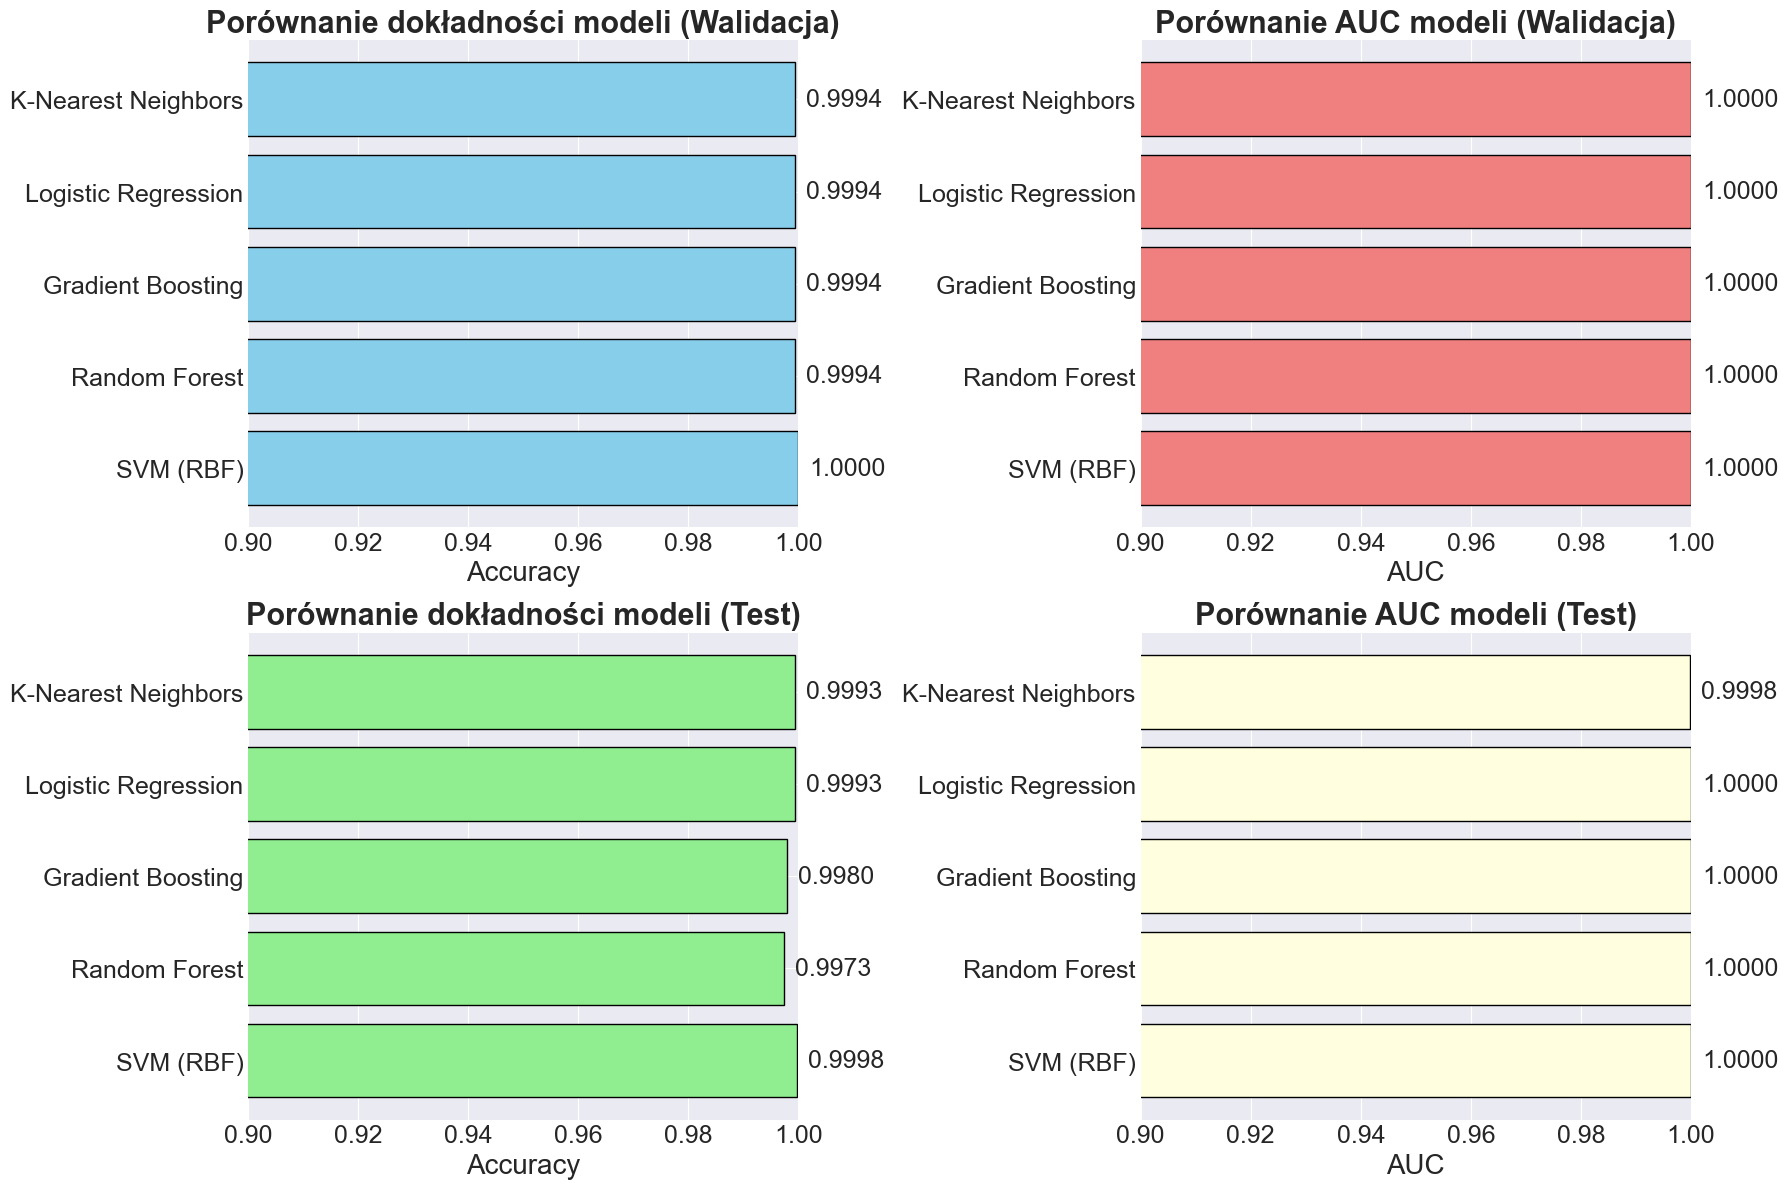

In [53]:
# Tabela porównawcza - zbiór walidacyjny
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Val_Accuracy': [results[m]['val_accuracy'] for m in results.keys()],
    'Val_AUC': [results[m]['val_auc'] for m in results.keys()],
    'Test_Accuracy': [results[m]['test_accuracy'] for m in results.keys()],
    'Test_AUC': [results[m]['test_auc'] for m in results.keys()]
})
comparison_df = comparison_df.sort_values('Val_Accuracy', ascending=False)

print("=== PORÓWNANIE MODELI (Zbiór walidacyjny i testowy) ===\n")
print(comparison_df.to_string(index=False))
print(f"\n{'='*70}")

# Wizualizacja porównania
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Wykres dokładności - walidacja
axes[0, 0].barh(comparison_df['Model'], comparison_df['Val_Accuracy'], color='skyblue', edgecolor='black')
axes[0, 0].set_xlabel('Accuracy', fontsize=font_size)
axes[0, 0].set_title('Porównanie dokładności modeli (Walidacja)', fontsize=font_size+2, fontweight='bold')
axes[0, 0].set_xlim([0.9, 1.0])
axes[0, 0].tick_params(axis='both', which='major', labelsize=font_size-2)
for i, v in enumerate(comparison_df['Val_Accuracy']):
    axes[0, 0].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=font_size-2)

# Wykres AUC - walidacja
axes[0, 1].barh(comparison_df['Model'], comparison_df['Val_AUC'], color='lightcoral', edgecolor='black')
axes[0, 1].set_xlabel('AUC', fontsize=font_size)
axes[0, 1].set_title('Porównanie AUC modeli (Walidacja)', fontsize=font_size+2, fontweight='bold')
axes[0, 1].set_xlim([0.9, 1.0])
axes[0, 1].tick_params(axis='both', which='major', labelsize=font_size-2)
for i, v in enumerate(comparison_df['Val_AUC']):
    axes[0, 1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=font_size-2)

# Wykres dokładności - test
axes[1, 0].barh(comparison_df['Model'], comparison_df['Test_Accuracy'], color='lightgreen', edgecolor='black')
axes[1, 0].set_xlabel('Accuracy', fontsize=font_size)
axes[1, 0].set_title('Porównanie dokładności modeli (Test)', fontsize=font_size+2, fontweight='bold')
axes[1, 0].set_xlim([0.9, 1.0])
axes[1, 0].tick_params(axis='both', which='major', labelsize=font_size-2)
for i, v in enumerate(comparison_df['Test_Accuracy']):
    axes[1, 0].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=font_size-2)

# Wykres AUC - test
axes[1, 1].barh(comparison_df['Model'], comparison_df['Test_AUC'], color='lightyellow', edgecolor='black')
axes[1, 1].set_xlabel('AUC', fontsize=font_size)
axes[1, 1].set_title('Porównanie AUC modeli (Test)', fontsize=font_size+2, fontweight='bold')
axes[1, 1].set_xlim([0.9, 1.0])
axes[1, 1].tick_params(axis='both', which='major', labelsize=font_size-2)
for i, v in enumerate(comparison_df['Test_AUC']):
    axes[1, 1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=font_size-2)

plt.tight_layout()
plt.show()

### 4.3. Szczegółowa analiza najlepszego modelu

=== NAJLEPSZY MODEL: SVM (RBF) ===

Walidacja - Accuracy: 1.0000, AUC: 1.0000
Test - Accuracy: 0.9998, AUC: 1.0000

=== Classification Report (Walidacja) ===
              precision    recall  f1-score   support

    JFIF (0)       1.00      1.00      1.00      1760
     PPM (1)       1.00      1.00      1.00      1814

    accuracy                           1.00      3574
   macro avg       1.00      1.00      1.00      3574
weighted avg       1.00      1.00      1.00      3574


=== Classification Report (Test) ===
              precision    recall  f1-score   support

    JFIF (0)       1.00      1.00      1.00      2200
     PPM (1)       1.00      1.00      1.00      2268

    accuracy                           1.00      4468
   macro avg       1.00      1.00      1.00      4468
weighted avg       1.00      1.00      1.00      4468



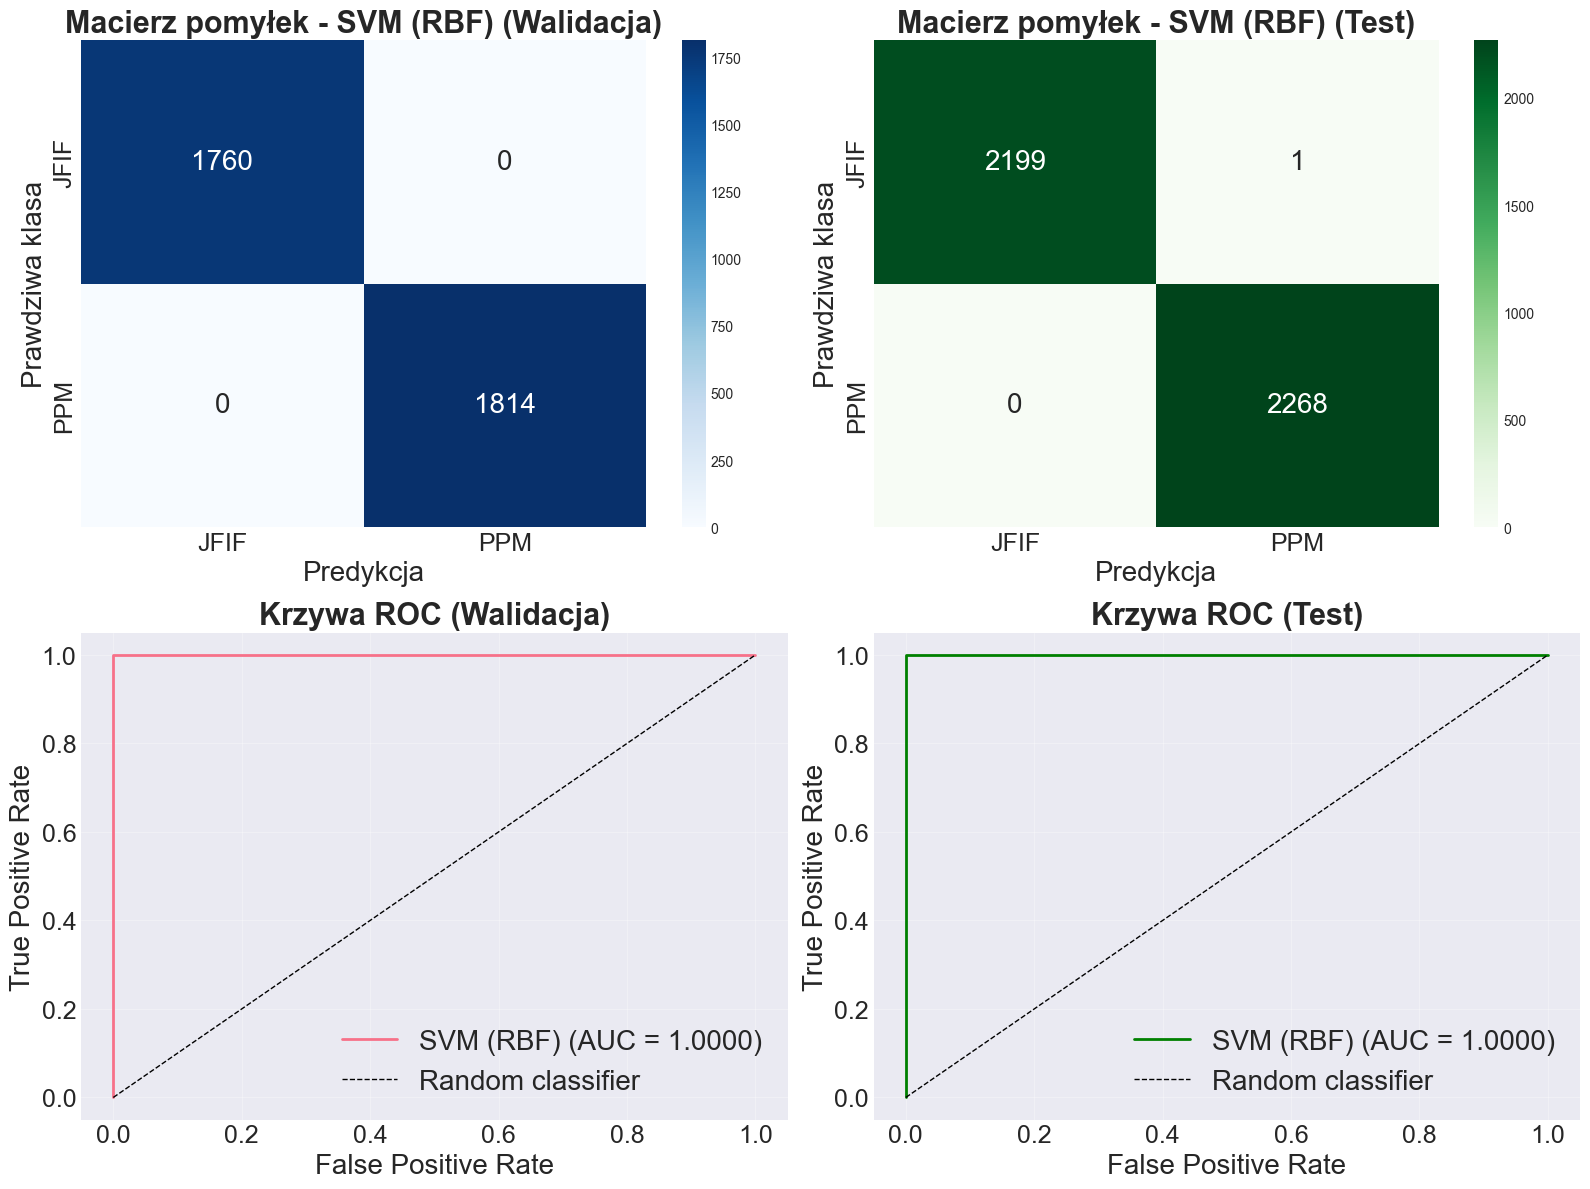

In [54]:
# Wybór najlepszego modelu (na podstawie walidacji)
best_model_name = comparison_df.iloc[0]['Model']
best_model_results = results[best_model_name]

print(f"=== NAJLEPSZY MODEL: {best_model_name} ===\n")
print(f"Walidacja - Accuracy: {best_model_results['val_accuracy']:.4f}, AUC: {best_model_results['val_auc']:.4f}")
print(f"Test - Accuracy: {best_model_results['test_accuracy']:.4f}, AUC: {best_model_results['test_auc']:.4f}\n")

# Raport klasyfikacji dla walidacji i testu
print("=== Classification Report (Walidacja) ===")
print(classification_report(y_val, best_model_results['y_val_pred'], 
                          target_names=['JFIF (0)', 'PPM (1)']))

print("\n=== Classification Report (Test) ===")
print(classification_report(y_test, best_model_results['y_test_pred'], 
                          target_names=['JFIF (0)', 'PPM (1)']))

# Macierz pomyłek dla obu zbiorów
cm_val = confusion_matrix(y_val, best_model_results['y_val_pred'])
cm_test = confusion_matrix(y_test, best_model_results['y_test_pred'])

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Macierz pomyłek - walidacja
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], 
            xticklabels=['JFIF', 'PPM'], yticklabels=['JFIF', 'PPM'], annot_kws={"fontsize": font_size})
axes[0, 0].set_xlabel('Predykcja', fontsize=font_size)
axes[0, 0].set_ylabel('Prawdziwa klasa', fontsize=font_size)
axes[0, 0].set_title(f'Macierz pomyłek - {best_model_name} (Walidacja)', fontsize=font_size+2, fontweight='bold')
axes[0, 0].tick_params(axis='both', which='major', labelsize=font_size-2)

# Macierz pomyłek - test
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', ax=axes[0, 1], 
            xticklabels=['JFIF', 'PPM'], yticklabels=['JFIF', 'PPM'], annot_kws={"fontsize": font_size})
axes[0, 1].set_xlabel('Predykcja', fontsize=font_size)
axes[0, 1].set_ylabel('Prawdziwa klasa', fontsize=font_size)
axes[0, 1].set_title(f'Macierz pomyłek - {best_model_name} (Test)', fontsize=font_size+2, fontweight='bold')
axes[0, 1].tick_params(axis='both', which='major', labelsize=font_size-2)

# Krzywa ROC - walidacja
fpr_val, tpr_val, _ = roc_curve(y_val, best_model_results['y_val_pred_proba'])
axes[1, 0].plot(fpr_val, tpr_val, linewidth=2, label=f'{best_model_name} (AUC = {best_model_results["val_auc"]:.4f})')
axes[1, 0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
axes[1, 0].set_xlabel('False Positive Rate', fontsize=font_size)
axes[1, 0].set_ylabel('True Positive Rate', fontsize=font_size)
axes[1, 0].set_title('Krzywa ROC (Walidacja)', fontsize=font_size+2, fontweight='bold')
axes[1, 0].legend(fontsize=font_size)
axes[1, 0].tick_params(axis='both', which='major', labelsize=font_size-2)
axes[1, 0].grid(True, alpha=0.3)

# Krzywa ROC - test
fpr_test, tpr_test, _ = roc_curve(y_test, best_model_results['y_test_pred_proba'])
axes[1, 1].plot(fpr_test, tpr_test, linewidth=2, label=f'{best_model_name} (AUC = {best_model_results["test_auc"]:.4f})', color='green')
axes[1, 1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
axes[1, 1].set_xlabel('False Positive Rate', fontsize=font_size)
axes[1, 1].set_ylabel('True Positive Rate', fontsize=font_size)
axes[1, 1].set_title('Krzywa ROC (Test)', fontsize=font_size+2, fontweight='bold')
axes[1, 1].legend(fontsize=font_size)
axes[1, 1].tick_params(axis='both', which='major', labelsize=font_size-2)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4. Ważność cech (dla modeli opartych na drzewach)

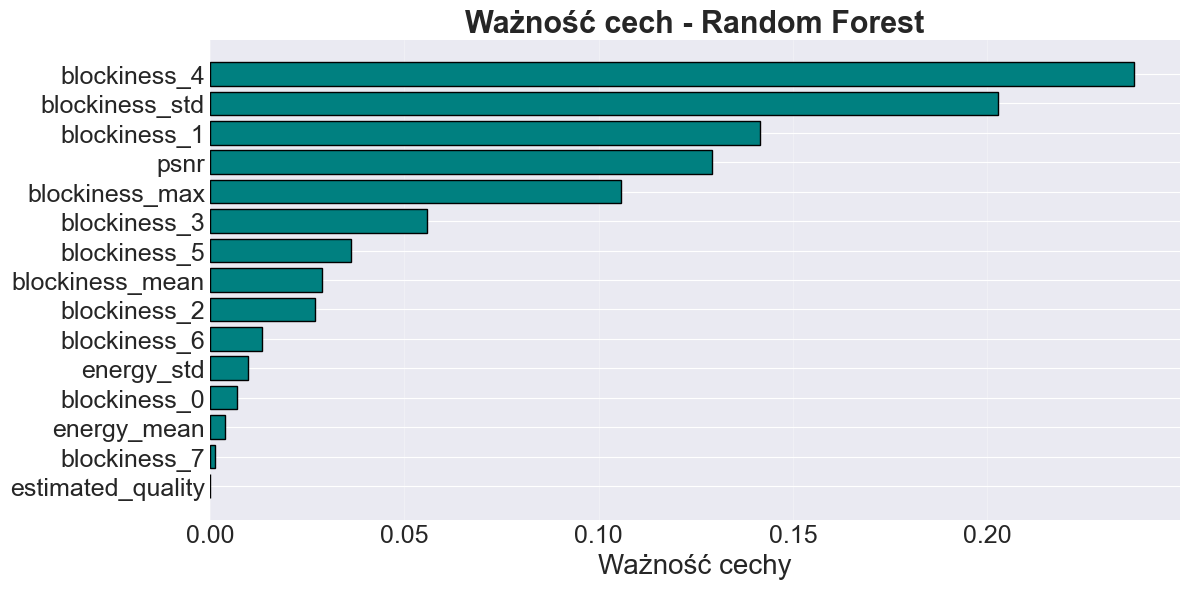


=== Top 5 najważniejszych cech dla Random Forest ===
1. blockiness_4: 0.2376
2. blockiness_std: 0.2026
3. blockiness_1: 0.1415
4. psnr: 0.1293
5. blockiness_max: 0.1057


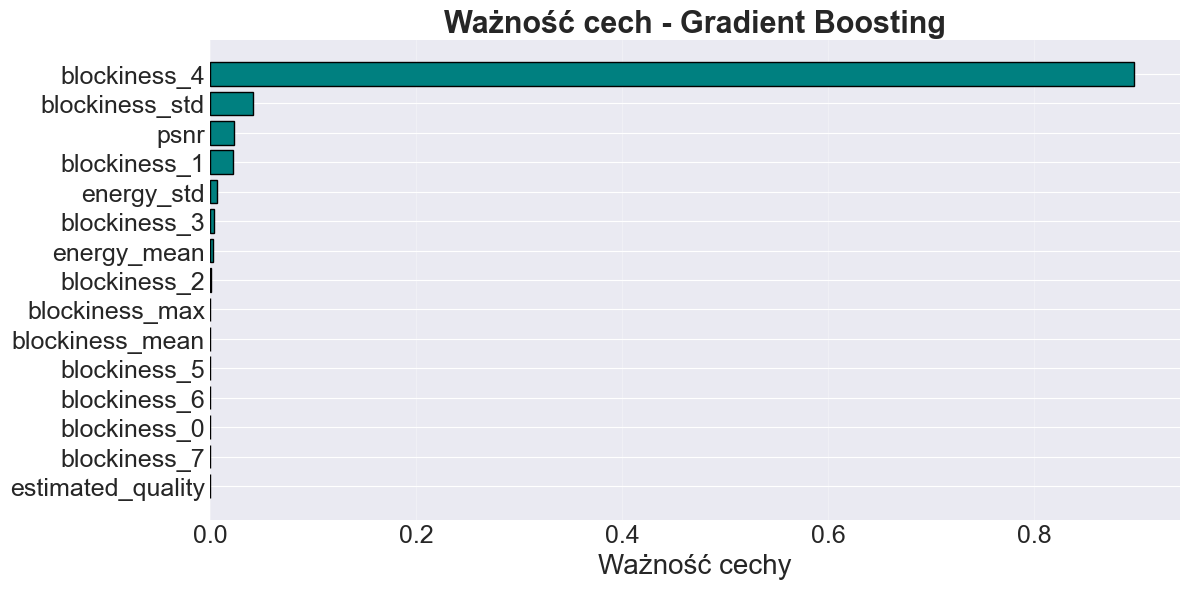


=== Top 5 najważniejszych cech dla Gradient Boosting ===
1. blockiness_4: 0.8966
2. blockiness_std: 0.0422
3. psnr: 0.0237
4. blockiness_1: 0.0226
5. energy_std: 0.0068


In [56]:
# Analiza ważności cech dla modeli opartych na drzewach
tree_based_models = ['Random Forest', 'Gradient Boosting']

for model_name in tree_based_models:
    if model_name in results:
        model = results[model_name]['model']
        
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            indices = np.argsort(importances)[::-1]
            
            plt.figure(figsize=(12, 6))
            plt.barh(range(len(importances)), importances[indices], color='teal', edgecolor='black')
            plt.yticks(range(len(importances)), [feature_columns[i] for i in indices], fontsize=font_size-2)
            plt.xlabel('Ważność cechy', fontsize=font_size)
            plt.title(f'Ważność cech - {model_name}', fontsize=font_size+2, fontweight='bold')
            plt.gca().invert_yaxis()
            plt.tick_params(axis='both', which='major', labelsize=font_size-2)
            plt.grid(True, alpha=0.3, axis='x')
            plt.tight_layout()
            plt.show()
            
            print(f"\n=== Top 5 najważniejszych cech dla {model_name} ===")
            for i in range(min(5, len(importances))):
                idx = indices[i]
                print(f"{i+1}. {feature_columns[idx]}: {importances[idx]:.4f}")

### 4.5. Zapisywanie najlepszego modelu do pliku

In [88]:
# Zapisywanie najlepszego modelu i skalera do plików
import os

# Tworzenie katalogu models/ jeśli nie istnieje
os.makedirs('models', exist_ok=True)

best_model = results[best_model_name]['model']

# Zapisz model
model_filename = f'models/best_model_{best_model_name.replace(" ", "_").lower()}.pkl'
joblib.dump(best_model, model_filename)
print(f"✓ Model '{best_model_name}' zapisany do pliku: {model_filename}")

# Zapisz skaler (StandardScaler)
scaler_filename = 'models/scaler.pkl'
joblib.dump(scaler, scaler_filename)
print(f"✓ Skaler zapisany do pliku: {scaler_filename}")

# Zapisz listę cech
features_filename = 'models/feature_columns.pkl'
joblib.dump(feature_columns, features_filename)
print(f"✓ Lista cech zapisana do pliku: {features_filename}")

# Zapisz wszystkie modele
all_models_filename = 'models/all_models.pkl'
all_models_dict = {name: results[name]['model'] for name in results.keys()}
joblib.dump(all_models_dict, all_models_filename)
print(f"✓ Wszystkie modele zapisane do pliku: {all_models_filename}")

print("\n" + "="*70)
print("Modele zapisane pomyślnie w katalogu 'models/'!")
print("="*70)
print("\nAby wczytać model w innym skrypcie, użyj:")
print(f"  model = joblib.load('{model_filename}')")
print(f"  scaler = joblib.load('{scaler_filename}')")
print(f"  feature_columns = joblib.load('{features_filename}')")

✓ Model 'SVM (RBF)' zapisany do pliku: models/best_model_svm_(rbf).pkl
✓ Skaler zapisany do pliku: models/scaler.pkl
✓ Lista cech zapisana do pliku: models/feature_columns.pkl
✓ Wszystkie modele zapisane do pliku: models/all_models.pkl

Modele zapisane pomyślnie w katalogu 'models/'!

Aby wczytać model w innym skrypcie, użyj:
  model = joblib.load('models/best_model_svm_(rbf).pkl')
  scaler = joblib.load('models/scaler.pkl')
  feature_columns = joblib.load('models/feature_columns.pkl')


## 5. Funkcja predykcji dla nowych obrazów

In [89]:
def classify_image(image_features, model_name='Random Forest'):
    """
    Klasyfikuje obraz na podstawie wskaźników jakości.
    
    Parametry:
    -----------
    image_features : dict lub pd.Series
        Słownik lub Series zawierający wskaźniki obrazu
    model_name : str
        Nazwa modelu do użycia (domyślnie: najlepszy model)
    
    Zwraca:
    --------
    dict : Wynik klasyfikacji z etykietą i pewnością
    """
    # Konwersja do DataFrame
    if isinstance(image_features, dict):
        features_df = pd.DataFrame([image_features])
    else:
        features_df = pd.DataFrame([image_features])
    
    # Upewnienie się, że mamy wszystkie wymagane cechy
    for col in feature_columns:
        if col not in features_df.columns:
            raise ValueError(f"Brakująca cecha: {col}")
    
    # Wybór tylko niezbędnych cech w odpowiedniej kolejności
    features_df = features_df[feature_columns]
    
    # Standaryzacja
    features_scaled = scaler.transform(features_df)
    
    # Wybór modelu
    if model_name not in results:
        print(f"Model '{model_name}' nie został znaleziony. Używam najlepszego modelu.")
        model_name = comparison_df.iloc[0]['Model']
    
    model = results[model_name]['model']
    
    # Predykcja
    prediction = model.predict(features_scaled)[0]
    probabilities = model.predict_proba(features_scaled)[0]
    # print(model.decision_function(features_scaled)) if hasattr(model, 'decision_function') else None
    
    # Interpretacja wyniku
    label = 'PPM' if prediction == 1 else 'JFIF'
    confidence = probabilities[prediction] * 100
    
    result = {
        'label': label,
        'confidence': confidence,
        'probabilities': {
            'JFIF': probabilities[0] * 100,
            'PPM': probabilities[1] * 100
        },
        'model_used': model_name
    }
    
    return result

# Przykład użycia
print("=== FUNKCJA KLASYFIKACJI GOTOWA ===\n")
print("Użycie: classify_image(image_features, model_name='Random Forest')")
print("\nimage_features powinno zawierać następujące wskaźniki:")
for i, col in enumerate(feature_columns, 1):
    print(f"  {i}. {col}")

=== FUNKCJA KLASYFIKACJI GOTOWA ===

Użycie: classify_image(image_features, model_name='Random Forest')

image_features powinno zawierać następujące wskaźniki:
  1. blockiness_0
  2. blockiness_1
  3. blockiness_2
  4. blockiness_3
  5. blockiness_4
  6. blockiness_5
  7. blockiness_6
  8. blockiness_7
  9. blockiness_max
  10. blockiness_mean
  11. blockiness_std
  12. energy_mean
  13. energy_std
  14. estimated_quality
  15. psnr


### 5.1. Test funkcji klasyfikacji

In [90]:
# Test na losowych próbkach ze zbioru testowego
print("=== TESTY FUNKCJI KLASYFIKACJI ===\n")

# Test 1: Losowy obraz JFIF
jfif_sample = df_jfif.sample(1).iloc[0]
test_features_jfif = jfif_sample[feature_columns].to_dict()

result_jfif = classify_image(test_features_jfif, best_model_name)
print(f"Test 1 - Rzeczywista klasa: JFIF")
print(f"Predykcja: {result_jfif['label']}")
print(f"Pewność: {result_jfif['confidence']:.2f}%")
print(f"Prawdopodobieństwa: JFIF={result_jfif['probabilities']['JFIF']:.2f}%, PPM={result_jfif['probabilities']['PPM']:.2f}%")
print(f"Model: {result_jfif['model_used']}\n")

# Test 2: Losowy obraz PPM
ppm_sample = df_ppm.sample(1).iloc[0]
test_features_ppm = ppm_sample[feature_columns].to_dict()

result_ppm = classify_image(test_features_ppm, best_model_name)
print(f"Test 2 - Rzeczywista klasa: PPM")
print(f"Predykcja: {result_ppm['label']}")
print(f"Pewność: {result_ppm['confidence']:.2f}%")
print(f"Prawdopodobieństwa: JFIF={result_ppm['probabilities']['JFIF']:.2f}%, PPM={result_ppm['probabilities']['PPM']:.2f}%")
print(f"Model: {result_ppm['model_used']}\n")

# Test 3: Kilka próbek
print("Test 3 - Klasyfikacja 10 losowych obrazów:")
print("-" * 80)
test_samples = df.sample(10)

for idx, row in test_samples.iterrows():
    true_label = row['label'].upper()
    features = row[feature_columns].to_dict()
    result = classify_image(features, best_model_name)
    
    status = "✓" if result['label'] == true_label else "✗"
    print(f"{status} Rzeczywista: {true_label:4s} | Predykcja: {result['label']:4s} | Pewność: {result['confidence']:6.2f}%")

=== TESTY FUNKCJI KLASYFIKACJI ===

Test 1 - Rzeczywista klasa: JFIF
Predykcja: JFIF
Pewność: 99.99%
Prawdopodobieństwa: JFIF=99.99%, PPM=0.01%
Model: SVM (RBF)

Test 2 - Rzeczywista klasa: PPM
Predykcja: PPM
Pewność: 100.00%
Prawdopodobieństwa: JFIF=0.00%, PPM=100.00%
Model: SVM (RBF)

Test 3 - Klasyfikacja 10 losowych obrazów:
--------------------------------------------------------------------------------
✓ Rzeczywista: PPM  | Predykcja: PPM  | Pewność: 100.00%
✓ Rzeczywista: PPM  | Predykcja: PPM  | Pewność: 100.00%
✓ Rzeczywista: PPM  | Predykcja: PPM  | Pewność: 100.00%
✓ Rzeczywista: PPM  | Predykcja: PPM  | Pewność: 100.00%
✓ Rzeczywista: PPM  | Predykcja: PPM  | Pewność: 100.00%
✓ Rzeczywista: JFIF | Predykcja: JFIF | Pewność: 100.00%
✓ Rzeczywista: JFIF | Predykcja: JFIF | Pewność: 100.00%
✓ Rzeczywista: JFIF | Predykcja: JFIF | Pewność:  99.99%
✓ Rzeczywista: JFIF | Predykcja: JFIF | Pewność: 100.00%
✓ Rzeczywista: PPM  | Predykcja: PPM  | Pewność: 100.00%
✓ Rzeczywista: PPM

## 5.2 Testy jednostkowe

In [91]:
from index_script import detect_jpeg_compression
import os

# features = detect_jpeg_compression("direct_camera_shot.png")
# features = detect_jpeg_compression("zrobione_recznie_injection.jpg")
# features = detect_jpeg_compression("direct_camera_shot_cam1.png")
# features = detect_jpeg_compression("test-images/1100x1100-woman.png")
# features = detect_jpeg_compression("test-images/00-swapped-woman.jpg")
features = detect_jpeg_compression("test-images/moje (6).jpg")
print(features)

result_single = classify_image(features, best_model_name)
print(f"Predykcja: {result_single['label']}")
print(f"Pewność: {result_single['confidence']:.2f}%")
print(f"Prawdopodobieństwa: JFIF={result_single['probabilities']['JFIF']:.2f}%, PPM={result_single['probabilities']['PPM']:.2f}%")
print(f"Model: {result_single['model_used']}\n")

print("\n=== KLASYFIKACJA KAŻDYM MODELEM ===\n")
for model_name in results.keys():
    result = classify_image(features, model_name)
    print(f"{model_name:25s} | Predykcja: {result['label']:4s} | Pewność: {result['confidence']:6.2f}% | JFIF: {result['probabilities']['JFIF']:6.2f}% | PPM: {result['probabilities']['PPM']:6.2f}%")

{'energy_mean': 210.19479370117188, 'energy_std': 283.1156311035156, 'estimated_quality': 95, 'psnr': 48.68933573700368, 'blockiness_mean': 1.0004379749298096, 'blockiness_max': 1.1261053085327148, 'blockiness_std': 0.0572778694331646, 'blockiness_0': 1.0105648040771484, 'blockiness_1': 0.9546548128128052, 'blockiness_2': 1.0109442472457886, 'blockiness_3': 0.9255262613296509, 'blockiness_4': 1.0182567834854126, 'blockiness_5': 0.9535007476806641, 'blockiness_6': 1.0039516687393188, 'blockiness_7': 1.1261053085327148}
Predykcja: JFIF
Pewność: 78.18%
Prawdopodobieństwa: JFIF=78.18%, PPM=21.82%
Model: SVM (RBF)


=== KLASYFIKACJA KAŻDYM MODELEM ===

Random Forest             | Predykcja: PPM  | Pewność:  82.00% | JFIF:  18.00% | PPM:  82.00%
Gradient Boosting         | Predykcja: JFIF | Pewność:  54.03% | JFIF:  54.03% | PPM:  45.97%
SVM (RBF)                 | Predykcja: JFIF | Pewność:  78.18% | JFIF:  78.18% | PPM:  21.82%
Logistic Regression       | Predykcja: JFIF | Pewność:  98.85%

## 5.3 Test małej próbki (katalog test-images/)

In [92]:
# from index_script import detect_jpeg_compression
# import os

# # Procesowanie katalogu
# image_files = [os.path.join("test-images", f) for f in os.listdir("test-images") if os.path.isfile(os.path.join("test-images", f))]
# # Process each image file
# for image_path in image_files:
#     print(f"\nAnalyzing: {image_path}")
#     try:
#         features = detect_jpeg_compression(image_path)
#         # print(features)

#         result_single = classify_image(features, best_model_name)
#         print(f"Predykcja: {result_single['label']}")
#         print(f"Pewność: {result_single['confidence']:.2f}%")
#         print(f"Prawdopodobieństwa: JFIF={result_single['probabilities']['JFIF']:.2f}%, PPM={result_single['probabilities']['PPM']:.2f}%")
#         print(f"Model: {result_single['model_used']}\n")
#     except Exception as e:
#         print(f"Error processing {image_path}: {e}")

## 6. Porównanie wszystkich modeli - krzywe ROC

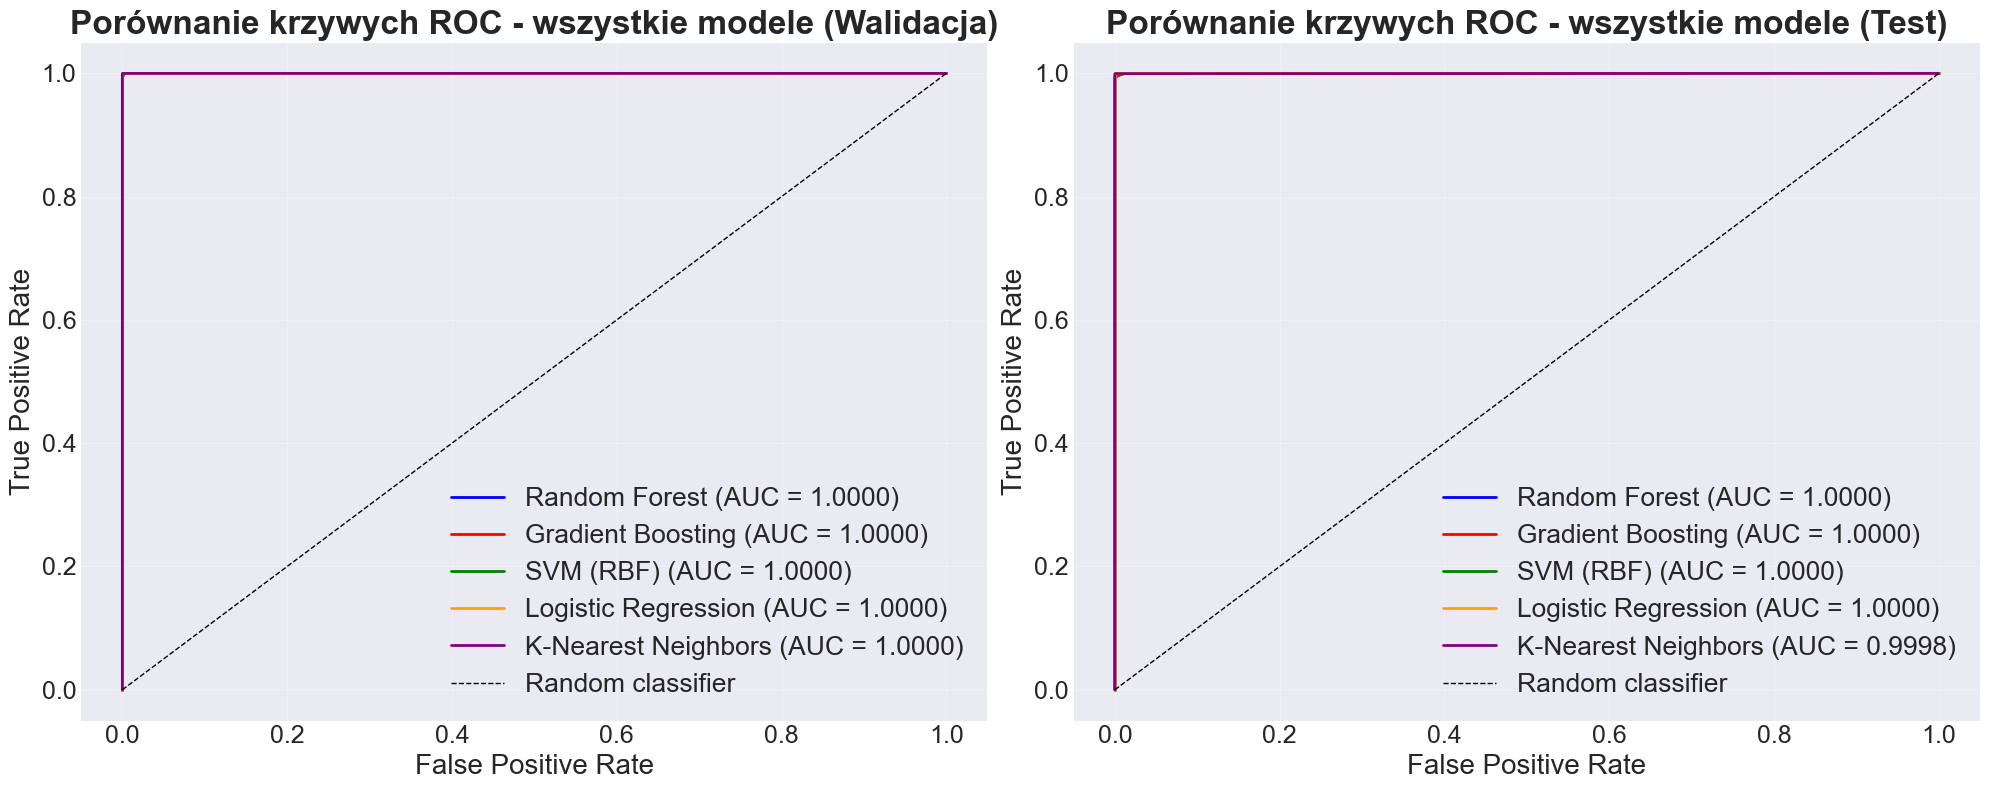

In [57]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

colors = ['blue', 'red', 'green', 'orange', 'purple']

# Krzywe ROC - walidacja
for (name, result), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_val, result['y_val_pred_proba'])
    ax1.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {result["val_auc"]:.4f})', color=color)

ax1.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
ax1.set_xlabel('False Positive Rate', fontsize=font_size)
ax1.set_ylabel('True Positive Rate', fontsize=font_size)
ax1.set_title('Porównanie krzywych ROC - wszystkie modele (Walidacja)', fontsize=font_size+4, fontweight='bold')
ax1.legend(fontsize=font_size-1, loc='lower right')
ax1.tick_params(axis='both', which='major', labelsize=font_size-2)
ax1.grid(True, alpha=0.3)

# Krzywe ROC - test
for (name, result), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, result['y_test_pred_proba'])
    ax2.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {result["test_auc"]:.4f})', color=color)

ax2.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
ax2.set_xlabel('False Positive Rate', fontsize=font_size)
ax2.set_ylabel('True Positive Rate', fontsize=font_size)
ax2.set_title('Porównanie krzywych ROC - wszystkie modele (Test)', fontsize=font_size+4, fontweight='bold')
ax2.legend(fontsize=font_size-1, loc='lower right')
ax2.tick_params(axis='both', which='major', labelsize=font_size-2)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Przykład wczytywania zapisanego modelu

In [94]:
# Przykład wczytywania zapisanego modelu do użycia w innym skrypcie
# 

# Wczytanie zapisanych plików z katalogu models/
# loaded_model = joblib.load('models/best_model_random_forest.pkl')
# loaded_scaler = joblib.load('models/scaler.pkl')
# loaded_feature_columns = joblib.load('models/feature_columns.pkl')

# print("✓ Model wczytany pomyślnie!")
# print(f"✓ Typ modelu: {type(loaded_model).__name__}")
# print(f"✓ Liczba cech: {len(loaded_feature_columns)}")

# # Przykładowa predykcja z wczytanym modelem
# # Przygotowanie danych testowych
# test_sample = X_test.iloc[0:1]  # Pierwsza próbka ze zbioru testowego
# test_sample_scaled = loaded_scaler.transform(test_sample)

# # Predykcja
# prediction = loaded_model.predict(test_sample_scaled)[0]
# probabilities = loaded_model.predict_proba(test_sample_scaled)[0]

# print(f"\nPredykcja: {'PPM' if prediction == 1 else 'JFIF'}")
# print(f"Prawdopodobieństwa: JFIF={probabilities[0]*100:.2f}%, PPM={probabilities[1]*100:.2f}%")